In [71]:
# Cell 1: Project Model Files Inspection

import os

print("=" * 55)
print("MODEL EXPLAINABILITY - PROJECT FILE INSPECTION")
print("=" * 55)

print("\nCurrent Working Directory:")
print(os.getcwd())

print("\nAvailable Model Files:")

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".venv"]
    ]

    for file in files:
        if file.endswith((".joblib", ".pkl")):
            print(os.path.join(root, file))

print("\nModel File Inspection Completed!")

MODEL EXPLAINABILITY - PROJECT FILE INSPECTION

Current Working Directory:
c:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\notebook

Available Model Files:
.\models\best_demand_regression_model.joblib
.\models\best_ev_demand_forecasting_model.joblib
.\models\demand_classification_model.joblib
.\models\ev_demand_forecasting_metadata.joblib

Model File Inspection Completed!


In [72]:
# Cell 2: Search Regression Model in Parent Project Directory

import os
import joblib

# Move from notebook folder to project root
project_root = os.path.dirname(os.getcwd())

model_filename = "best_demand_regression_model.joblib"

found_model = None

for root, dirs, files in os.walk(project_root):

    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", ".venv"]
    ]

    if model_filename in files:
        found_model = os.path.join(root, model_filename)
        break

if found_model:

    regression_model = joblib.load(found_model)

    print("Regression Model Loaded Successfully!")
    print("Model Path:", found_model)
    print("Model Type:", type(regression_model).__name__)

else:

    print("Regression Model Not Found!")
    print("Searched Directory:", project_root)

    print("\nAvailable Model Files:")

    for root, dirs, files in os.walk(project_root):
        for file in files:
            if file.endswith((".joblib", ".pkl")):
                print(os.path.join(root, file))

Regression Model Loaded Successfully!
Model Path: c:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\models\best_demand_regression_model.joblib
Model Type: Pipeline


In [73]:
# Cell 3: Load Cleaned Regression Dataset

import pandas as pd
import os

project_root = os.path.dirname(os.getcwd())

dataset_path = os.path.join(
    project_root,
    "data",
    "processed",
    "ChargingRecords_cleaned.csv"
)

if os.path.exists(dataset_path):

    regression_df = pd.read_csv(dataset_path)

    print("Regression Dataset Loaded Successfully!")
    print("Dataset Shape:", regression_df.shape)

    print("\nDataset Columns:")
    print(regression_df.columns.tolist())

    print("\nDataset Preview:")
    display(regression_df.head())

else:
    print("Cleaned Dataset Not Found!")
    print("Expected Path:", dataset_path)

Regression Dataset Loaded Successfully!
Dataset Shape: (72799, 13)

Dataset Columns:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']

Dataset Preview:


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:02,2022-09-15 23:59:13,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:05,2022-09-14 21:31:04,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:30,2022-09-14 19:54:29,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:51,2022-09-30 00:16:42,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:15,2022-09-26 00:30:14,300,33.81


In [74]:
# Cell 4: Inspect Regression Model Features

print("=" * 55)
print("REGRESSION MODEL FEATURE INSPECTION")
print("=" * 55)

if hasattr(regression_model, "feature_names_in_"):

    regression_features = list(
        regression_model.feature_names_in_
    )

    print("\nModel Training Features:")
    print(regression_features)

else:

    print("\nFeature names are not stored in the model.")

    if hasattr(regression_model, "n_features_in_"):
        print("Number of Features:",
              regression_model.n_features_in_)

if "regression_df" in globals():

    print("\nDataset Columns:")
    print(regression_df.columns.tolist())

    print("\nDataset Shape:", regression_df.shape)

print("\nFeature Inspection Completed!")

REGRESSION MODEL FEATURE INSPECTION

Model Training Features:
['ChargerCompany', 'Location', 'ChargerType', 'StartHour', 'DayOfWeek', 'Month', 'IsWeekend']

Dataset Columns:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']

Dataset Shape: (72799, 13)

Feature Inspection Completed!


In [75]:
# Cell 5: Verify Model and Dataset Compatibility

print("=" * 60)
print("MODEL AND DATASET COMPATIBILITY CHECK")
print("=" * 60)

if hasattr(regression_model, "feature_names_in_"):

    regression_features = list(
        regression_model.feature_names_in_
    )

    available_features = regression_df.columns.tolist()

    missing_features = [
        feature for feature in regression_features
        if feature not in available_features
    ]

    print("Total Model Features:", len(regression_features))
    print("Available Dataset Columns:", len(available_features))

    if len(missing_features) == 0:
        print("\nAll model features are available!")
    else:
        print("\nMissing Features:", missing_features)

else:
    print("Model does not store original feature names.")
    print("Input Feature Count:",
          getattr(regression_model, "n_features_in_", "Unknown"))

print("\nDataset Shape:", regression_df.shape)
print("\nCompatibility Check Completed!")

MODEL AND DATASET COMPATIBILITY CHECK
Total Model Features: 7
Available Dataset Columns: 13

Missing Features: ['StartHour', 'DayOfWeek', 'Month', 'IsWeekend']

Dataset Shape: (72799, 13)

Compatibility Check Completed!


In [76]:
# Cell 6: Create Missing Model Features

# Create a working copy
shap_df = regression_df.copy()

# Convert StartDatetime if available
if "StartDatetime" in shap_df.columns:

    shap_df["StartDatetime"] = pd.to_datetime(
        shap_df["StartDatetime"],
        errors="coerce"
    )

    shap_df["StartHour"] = shap_df["StartDatetime"].dt.hour
    shap_df["DayOfWeek"] = shap_df["StartDatetime"].dt.dayofweek
    shap_df["Month"] = shap_df["StartDatetime"].dt.month

    shap_df["IsWeekend"] = (
        shap_df["DayOfWeek"] >= 5
    ).astype(int)

else:
    raise ValueError(
        "StartDatetime column not found. "
        "Cannot safely recreate the original time features."
    )

# Check required model features
missing_features = [
    col for col in regression_features
    if col not in shap_df.columns
]

if missing_features:
    raise ValueError(
        f"Still missing features: {missing_features}"
    )

# Prepare SHAP input in exact model feature order
X_shap = shap_df[regression_features].copy()

X_shap = X_shap.dropna()

X_shap = X_shap.sample(
    n=min(500, len(X_shap)),
    random_state=42
)

print("SHAP Features Prepared Successfully!")
print("Feature Count:", len(regression_features))
print("SHAP Dataset Shape:", X_shap.shape)

display(X_shap.head())

SHAP Features Prepared Successfully!
Feature Count: 7
SHAP Dataset Shape: (500, 7)


,ChargerCompany,Location,ChargerType,StartHour,DayOfWeek,Month,IsWeekend
20768,1,hotel,0,19,2,8,0
57366,0,public area,1,15,2,7,0
71972,0,sightseeing,1,12,6,4,1
46050,1,company,0,8,3,4,0
28676,1,public area,0,11,3,10,0


In [77]:
# Cell 7: Install and Import SHAP

%pip install shap -q

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("SHAP Library Imported Successfully!")
print("SHAP Version:", shap.__version__)

Note: you may need to restart the kernel to use updated packages.
SHAP Library Imported Successfully!
SHAP Version: 0.54.1



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\kavee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [78]:
# Cell 8: Apply Pipeline Preprocessing and Calculate SHAP

# Extract preprocessing and final model
preprocessor = regression_model[:-1]
final_model = regression_model.steps[-1][1]

# Transform the SHAP dataset
X_transformed = preprocessor.transform(X_shap)

# Convert transformed data into DataFrame
if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

feature_names = preprocessor.get_feature_names_out()

X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_shap.index
)

# Create SHAP explainer
explainer = shap.TreeExplainer(final_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_transformed_df)

print("SHAP Calculation Successful!")
print("Transformed Dataset Shape:", X_transformed_df.shape)
print("SHAP Values Shape:", np.array(shap_values).shape)
print("Transformed Features:", list(X_transformed_df.columns))

SHAP Calculation Successful!
Transformed Dataset Shape: (500, 7)
SHAP Values Shape: (500, 7)
Transformed Features: ['categorical__ChargerCompany', 'categorical__Location', 'categorical__ChargerType', 'numeric__StartHour', 'numeric__DayOfWeek', 'numeric__Month', 'numeric__IsWeekend']


C:\Users\kavee\AppData\Local\Temp\ipykernel_8664\1237600335.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


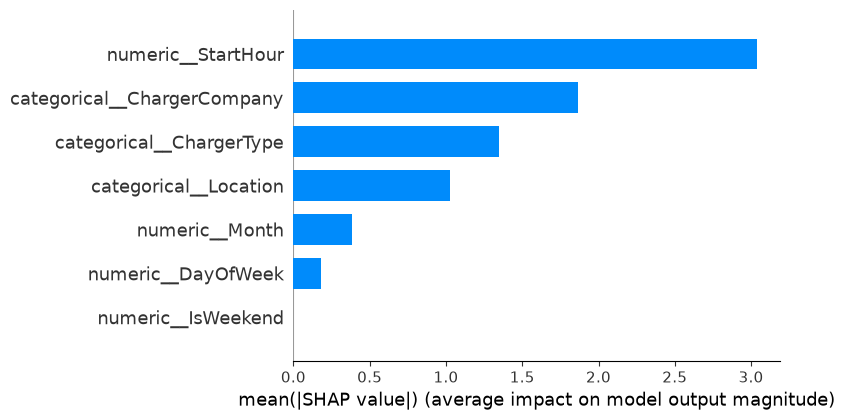

SHAP Feature Importance Generated Successfully!


In [79]:
# Cell 9: Global Feature Importance using SHAP

shap.summary_plot(
    shap_values,
    X_transformed_df,
    plot_type="bar",
    show=True
)

print("SHAP Feature Importance Generated Successfully!")

C:\Users\kavee\AppData\Local\Temp\ipykernel_8664\2103294828.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


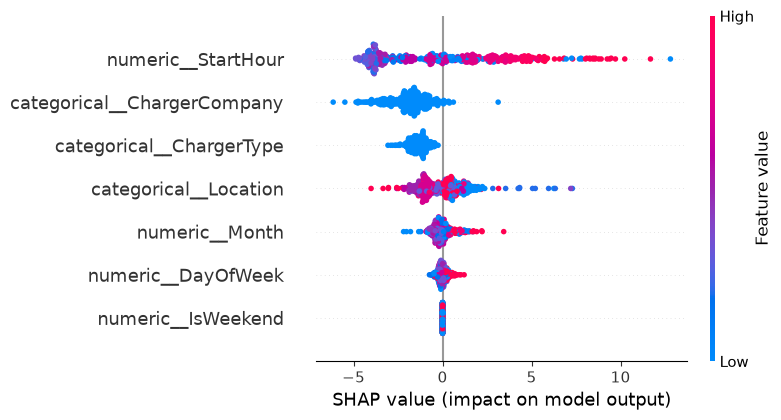

SHAP Summary Plot Generated Successfully!


In [80]:
# Cell 10: SHAP Summary Plot

shap.summary_plot(
    shap_values,
    X_transformed_df,
    show=True
)

print("SHAP Summary Plot Generated Successfully!")

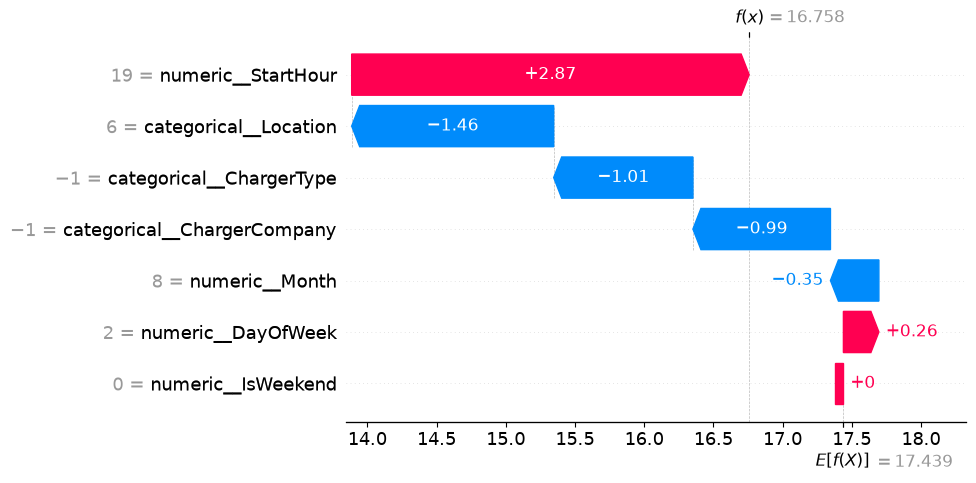

Individual SHAP Explanation Generated Successfully!


In [81]:
# Cell 11: SHAP Waterfall Plot

sample_index = 0

# Get SHAP values for one record
base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.array(base_value).flatten()[0]

shap_explanation = shap.Explanation(
    values=shap_values[sample_index],
    base_values=base_value,
    data=X_transformed_df.iloc[sample_index].values,
    feature_names=X_transformed_df.columns.tolist()
)

shap.plots.waterfall(shap_explanation, max_display=10)

print("Individual SHAP Explanation Generated Successfully!")

In [82]:
# Cell 12: Install and Import LIME

%pip install lime -q

from lime.lime_tabular import LimeTabularExplainer

print("LIME Library Imported Successfully!")

Note: you may need to restart the kernel to use updated packages.
LIME Library Imported Successfully!



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\kavee\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [83]:
# Cell 13: Create LIME Explainer

lime_explainer = LimeTabularExplainer(
    training_data=X_transformed_df.values,
    feature_names=X_transformed_df.columns.tolist(),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

print("LIME Explainer Created Successfully!")

LIME Explainer Created Successfully!


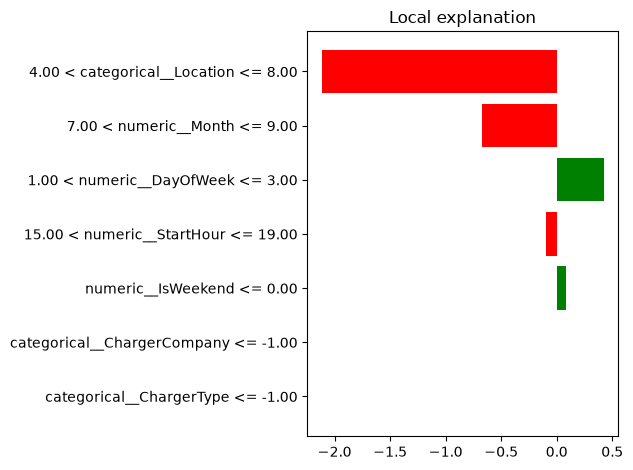

LIME Individual Explanation Generated Successfully!


In [84]:
# Cell 14: Generate LIME Individual Explanation

# Create LIME explainer using transformed numerical data
lime_explainer = LimeTabularExplainer(
    training_data=X_transformed_df.values,
    feature_names=X_transformed_df.columns.tolist(),
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

# Prediction function using the final model
def predict_transformed(data):
    return final_model.predict(data)

# Select one sample
sample_index = 0

# Generate explanation
lime_exp = lime_explainer.explain_instance(
    X_transformed_df.iloc[sample_index].values,
    predict_transformed,
    num_features=7
)

# Display LIME explanation as a Matplotlib figure

fig = lime_exp.as_pyplot_figure()
plt.tight_layout()
plt.show()

print("LIME Individual Explanation Generated Successfully!")


In [85]:
# Cell 15: Save SHAP and LIME Results

import os
import joblib
import pandas as pd
import numpy as np

# Create output directory
output_dir = os.path.join(project_root, "outputs", "explainability")
os.makedirs(output_dir, exist_ok=True)

# Save SHAP values
shap_df = pd.DataFrame(
    shap_values,
    columns=X_transformed_df.columns
)

shap_df.to_csv(
    os.path.join(output_dir, "regression_shap_values.csv"),
    index=False
)

# Save SHAP feature importance
shap_importance = pd.DataFrame({
    "Feature": X_transformed_df.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

shap_importance.to_csv(
    os.path.join(output_dir, "regression_shap_feature_importance.csv"),
    index=False
)

# Save LIME explanation
lime_results = pd.DataFrame(
    lime_exp.as_list(),
    columns=["Feature", "Contribution"]
)

lime_results.to_csv(
    os.path.join(output_dir, "regression_lime_explanation.csv"),
    index=False
)

print("Explainability Results Saved Successfully!")
print("Output Directory:", output_dir)
print("\nSaved Files:")
print(os.listdir(output_dir))

Explainability Results Saved Successfully!
Output Directory: c:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\outputs\explainability

Saved Files:
['classification_lime_explanation.csv', 'classification_prediction_result.csv', 'regression_lime_explanation.csv', 'regression_shap_feature_importance.csv', 'regression_shap_values.csv']


In [86]:
# Cell 16: Inspect Available Classification Models

import os

models_dir = os.path.join(project_root, "models")

print("=" * 55)
print("SAVED MODEL INSPECTION")
print("=" * 55)

if os.path.exists(models_dir):
    model_files = [
        file for file in os.listdir(models_dir)
        if file.endswith((".joblib", ".pkl"))
    ]

    if model_files:
        for file in model_files:
            print("Model Found:", file)
    else:
        print("No saved models found.")
else:
    print("Models directory not found:", models_dir)

print("\nModel Inspection Completed!")

SAVED MODEL INSPECTION
Model Found: best_demand_classification_model.joblib
Model Found: best_demand_regression_model.joblib
Model Found: demand_classification_model.joblib

Model Inspection Completed!


In [87]:
# Cell 17: Load Best Classification Model

import joblib
import os

classification_model_path = os.path.join(
    models_dir,
    "best_demand_classification_model.joblib"
)

classification_model = joblib.load(classification_model_path)

print("Classification Model Loaded Successfully!")
print("Model Type:", type(classification_model).__name__)
print("Model Path:", classification_model_path)

if hasattr(classification_model, "named_steps"):
    print("\nPipeline Steps:")
    for name, step in classification_model.named_steps.items():
        print(name, ":", type(step).__name__)

Classification Model Loaded Successfully!
Model Type: Pipeline
Model Path: c:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\models\best_demand_classification_model.joblib

Pipeline Steps:
preprocessor : ColumnTransformer
classifier : XGBClassifier


In [88]:
# Cell 18: Classification Feature Inspection

print("=" * 55)
print("CLASSIFICATION MODEL FEATURE INSPECTION")
print("=" * 55)

# Get expected training features
classification_features = list(
    classification_model.feature_names_in_
)

print("\nModel Training Features:")
print(classification_features)

print("\nDataset Columns:")
print(regression_df.columns.tolist())

# Check missing features
missing_features = [
    col for col in classification_features
    if col not in regression_df.columns
]

print("\nMissing Features:", missing_features)

print("\nDataset Shape:", regression_df.shape)
print("\nFeature Inspection Completed!")

CLASSIFICATION MODEL FEATURE INSPECTION

Model Training Features:
['ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime']

Dataset Columns:
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand']

Missing Features: []

Dataset Shape: (72799, 13)

Feature Inspection Completed!


In [89]:
# Cell 19: Prepare Classification SHAP Dataset

# Select the exact features used during model training
X_classification = regression_df[classification_features].copy()

# Remove rows with missing feature values
X_classification = X_classification.dropna()

# Select 500 records for explainability
X_classification_sample = X_classification.sample(
    n=min(500, len(X_classification)),
    random_state=42
)

# Extract preprocessing pipeline and classifier
classification_preprocessor = classification_model.named_steps["preprocessor"]
final_classifier = classification_model.named_steps["classifier"]

# Apply the original preprocessing
X_classification_transformed = classification_preprocessor.transform(
    X_classification_sample
)

# Convert sparse output if necessary
if hasattr(X_classification_transformed, "toarray"):
    X_classification_transformed = X_classification_transformed.toarray()

# Get transformed feature names
classification_feature_names = (
    classification_preprocessor.get_feature_names_out()
)

# Create transformed DataFrame
X_classification_transformed_df = pd.DataFrame(
    X_classification_transformed,
    columns=classification_feature_names,
    index=X_classification_sample.index
)

print("Classification SHAP Dataset Prepared Successfully!")
print("Original Features:", len(classification_features))
print("Transformed Features:", X_classification_transformed_df.shape[1])
print("Dataset Shape:", X_classification_transformed_df.shape)

display(X_classification_transformed_df.head())

Classification SHAP Dataset Prepared Successfully!
Original Features: 5
Transformed Features: 38376
Dataset Shape: (500, 38376)


,num__ChargerCompany,num__ChargerType,cat__Location_accommodation,cat__Location_apartment,cat__Location_bus garage,cat__Location_camping,cat__Location_company,cat__Location_golf,cat__Location_hotel,cat__Location_market,...,cat__StartTime_9:59:46,cat__StartTime_9:59:47,cat__StartTime_9:59:48,cat__StartTime_9:59:50,cat__StartTime_9:59:51,cat__StartTime_9:59:52,cat__StartTime_9:59:53,cat__StartTime_9:59:56,cat__StartTime_9:59:57,cat__StartTime_9:59:58
20768,0.771688,-0.507721,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
57366,-1.295861,1.969587,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
71972,-1.295861,1.969587,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
46050,0.771688,-0.507721,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
28676,0.771688,-0.507721,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [90]:
# Cell 20: Prepare Numerical Input for Classification SHAP

from sklearn.preprocessing import OrdinalEncoder

# Copy original classification data
X_class_numeric = X_classification.copy()

# Encode categorical columns
categorical_cols = X_class_numeric.select_dtypes(
    include=["object", "category"]
).columns.tolist()

classification_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

if categorical_cols:
    X_class_numeric[categorical_cols] = (
        classification_encoder.fit_transform(
            X_class_numeric[categorical_cols].astype(str)
        )
    )

# Ensure all features are numeric
X_class_numeric = X_class_numeric.astype(float)

# Select small samples for SHAP
X_background = X_class_numeric.sample(
    n=min(20, len(X_class_numeric)),
    random_state=42
)

X_classification_explain = X_class_numeric.sample(
    n=min(10, len(X_class_numeric)),
    random_state=21
)

print("Numerical Classification Data Prepared!")
print("Categorical Columns Encoded:", categorical_cols)
print("Background Shape:", X_background.shape)
print("Explanation Shape:", X_classification_explain.shape)
print("All Numeric:", X_class_numeric.dtypes.apply(
    lambda dtype: np.issubdtype(dtype, np.number)
).all())

C:\Users\kavee\AppData\Local\Temp\ipykernel_8664\3059480946.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_class_numeric.select_dtypes(


Numerical Classification Data Prepared!
Categorical Columns Encoded: ['Location', 'StartDay', 'StartTime']
Background Shape: (20, 5)
Explanation Shape: (10, 5)
All Numeric: True


In [91]:
# Cell 21: Setup LIME for Classification Model

from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd

# Identify categorical feature positions
classification_features = X_class_numeric.columns.tolist()

categorical_feature_indices = [
    classification_features.index(col)
    for col in categorical_cols
]

# Prepare category names for LIME
categorical_names = {
    classification_features.index(col): list(
        range(len(classification_encoder.categories_[i]))
    )
    for i, col in enumerate(categorical_cols)
}

# Create LIME Explainer
classification_lime_explainer = LimeTabularExplainer(
    training_data=X_class_numeric.values,
    feature_names=classification_features,
    categorical_features=categorical_feature_indices,
    categorical_names=categorical_names,
    class_names=[
        str(label) for label in classification_model.classes_
    ],
    mode="classification",
    random_state=42
)

print("Classification LIME Explainer Created Successfully!")
print("Features:", classification_features)
print("Categorical Feature Positions:", categorical_feature_indices)
print("Classes:", classification_model.classes_)

Classification LIME Explainer Created Successfully!
Features: ['ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime']
Categorical Feature Positions: [1, 3, 4]
Classes: [0 1]


In [92]:
# Cell 22: Classification LIME Prediction Function

def classification_predict_fn(data):

    lime_df = pd.DataFrame(
        data,
        columns=classification_features
    )

    # Decode categorical columns
    for i, col in enumerate(categorical_cols):

        categories = classification_encoder.categories_[i]

        encoded_values = np.rint(
            lime_df[col].values
        ).astype(int)

        decoded_values = []

        for value in encoded_values:
            value = np.clip(value, 0, len(categories) - 1)
            decoded_values.append(categories[value])

        lime_df[col] = decoded_values

    # Convert numeric columns to original numeric type
    for col in classification_features:
        if col not in categorical_cols:
            lime_df[col] = pd.to_numeric(lime_df[col])

    # Get classification probabilities
    probabilities = classification_model.predict_proba(lime_df)

    return probabilities


print("Classification Prediction Function Created!")
print("Prediction Output Shape:",
      classification_predict_fn(
          X_class_numeric.iloc[:5].values
      ).shape)

Classification Prediction Function Created!
Prediction Output Shape: (5, 2)


Classification LIME Explanation Generated!
Actual Class: 1
Predicted Class: 1


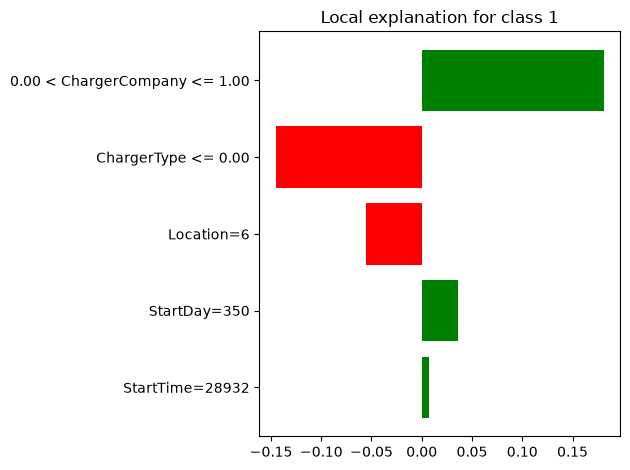

Classification LIME Visualization Generated Successfully!


In [93]:
# Cell 23: Generate Classification LIME Explanation

sample_index = 0

lime_classification_exp = classification_lime_explainer.explain_instance(
    data_row=X_class_numeric.iloc[sample_index].values,
    predict_fn=classification_predict_fn,
    num_features=5,
    top_labels=1,
    num_samples=1000
)

predicted_class = classification_model.predict(
    X_classification.iloc[[sample_index]]
)[0]

print("Classification LIME Explanation Generated!")
print("Actual Class:", classification_model.predict(
    X_classification.iloc[[sample_index]]
)[0])
print("Predicted Class:", predicted_class)

import matplotlib.pyplot as plt

fig = lime_classification_exp.as_pyplot_figure(label=1)

plt.tight_layout()
plt.show()

print("Classification LIME Visualization Generated Successfully!")

In [94]:
# Cell 24: Save Classification Explainability Results

import os

explainability_dir = os.path.join(
    project_root, "outputs", "explainability"
)

os.makedirs(explainability_dir, exist_ok=True)

# Save LIME explanation
classification_lime_df = pd.DataFrame(
    lime_classification_exp.as_list(label=1),
    columns=["Feature", "Importance"]
)

classification_lime_df.to_csv(
    os.path.join(
        explainability_dir,
        "classification_lime_explanation.csv"
    ),
    index=False
)

# Save classification prediction details
classification_result = pd.DataFrame({
    "Actual_Class": [
        classification_model.predict(
            X_classification.iloc[[sample_index]]
        )[0]
    ],
    "Predicted_Class": [
        predicted_class
    ]
})

classification_result.to_csv(
    os.path.join(
        explainability_dir,
        "classification_prediction_result.csv"
    ),
    index=False
)

print("Classification Explainability Results Saved!")
print("Saved Location:", explainability_dir)
print("Files:")
print("- classification_lime_explanation.csv")
print("- classification_prediction_result.csv")

Classification Explainability Results Saved!
Saved Location: c:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\outputs\explainability
Files:
- classification_lime_explanation.csv
- classification_prediction_result.csv


In [95]:
# Cell 25: Final Model Explainability Summary

print("=" * 60)
print("EV CHARGING DEMAND - MODEL EXPLAINABILITY SUMMARY")
print("=" * 60)

print("\nREGRESSION EXPLAINABILITY")
print("- SHAP Feature Importance: Saved")
print("- SHAP Summary Plot: Generated")
print("- SHAP Waterfall Plot: Generated")
print("- LIME Explanation: Saved")

print("\nCLASSIFICATION EXPLAINABILITY")
print("- LIME Explanation: Saved")
print("- Classification Prediction Result: Saved")

print("\nOUTPUT DIRECTORY")
print(explainability_dir)

print("\nMODEL EXPLAINABILITY WORKFLOW COMPLETED!")
print("=" * 60)

EV CHARGING DEMAND - MODEL EXPLAINABILITY SUMMARY

REGRESSION EXPLAINABILITY
- SHAP Feature Importance: Saved
- SHAP Summary Plot: Generated
- SHAP Waterfall Plot: Generated
- LIME Explanation: Saved

CLASSIFICATION EXPLAINABILITY
- LIME Explanation: Saved
- Classification Prediction Result: Saved

OUTPUT DIRECTORY
c:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\outputs\explainability

MODEL EXPLAINABILITY WORKFLOW COMPLETED!
